In [1]:
import sys
import h5py
import numpy as np
import scipy
import matplotlib.pyplot as plt
import healpy as hp

%matplotlib inline

NSIDE = 32
print(
    'Approximate resolution at NSIDE {} is {:.2} deg'.format(
        NSIDE, hp.nside2resol(NSIDE, arcmin=True) / 60
    )
)

NPIX = hp.nside2npix(NSIDE)
print(NPIX)
   
m = np.arange(NPIX)
hp.mollview(m, title="Mollview image RING")
hp.graticule()

In [2]:
filename = ( '/data/wiay/gw-data-releases/2026/19500064/'
    'samples-rpo4ab-1366933504-55469568-clipped.hdf') #shorthand to make finding the data easier, long path is a pain to work with 

I've changed how this cell runs to use array slicing instead of the really big for loop. Still shows an inhomogeneous distribution but I'm pretty sure this is due to the hopeless SNR cutoff already being imposed.

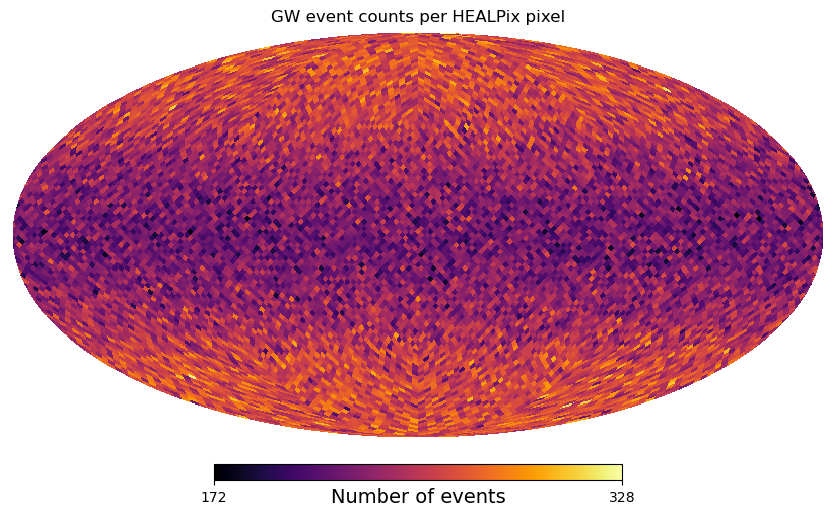

In [16]:
nside = 32 #mediocre number of pixels, good for first pass but I'd like to increase as the project continues 
npix = hp.nside2npix(nside) # this gives the number of pixels on the map (far as i can tell)
chunk_size = 500_000 #everything I tried last week was taking too long so im splitting it into chunks to make it more manageable

counts = np.zeros(npix, dtype=np.float64) #this line makes an empty array of pixels that will update as events fall into them, which i can call on later once its full (NEWLY CHANGED TO FLOAT FOR WHEN I START TO INCLUDE WEIGHTING)

with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    ra = events.fields('right_ascension')[:]
    dec = events.fields('declination')[:]
    valid = np.isfinite(ra) & np.isfinite(dec)
    pixels = hp.ang2pix(nside, np.pi/2 - dec, ra, lonlat = False)
    counts = np.bincount(pixels, minlength=npix)

hp.mollview(
    counts,
    title='GW event counts per HEALPix pixel',
    unit='Number of events',
    cmap='inferno'
)
plt.show()


IGNORE THIS CELL FOR THE MOMENT ITS NOT ANY USE 


nside = 128 #mediocre number of pixels, good for first pass but I'd like to increase as the project continues 
npix = hp.nside2npix(nside) # this gives the number of pixels on the map (far as i can tell)
chunk_size = 10_000 #everything I tried last week was taking too long so im splitting it into chunks to make it more manageable

snr_sum = np.zeros(npix, dtype=np.float64)
snr_count = np.zeros(npix, dtype=np.int64) #this line makes an empty array of pixels that will update as events fall into them, which i can call on later once its full 



with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    n_events = len(events) # defining number of events

    for start in range(0, n_events, chunk_size): #making sure it only goes one chunk at a time 
        stop = min(start + chunk_size, n_events)

        ra = events['right_ascension'][start:stop] #defining what columns to look at  
        dec = events['declination'][start:stop]
        snr = events['gstlal_rec_snr_net'][start:stop]

        valid = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(snr) #this just checks that the coordinate isnt nonsense
        ra = ra[valid]
        dec = dec[valid]
        snr = snr[valid]

        chunk_mean_snr = np.mean(snr) if len(snr) > 0 else np.nan
        
        print(
            f"Chunk {start:,}–{stop:,}: "
            f"mean SNR = {chunk_mean_snr:.3f}, "
            f"valid injections = {len(snr):,}"
    )

        ra_deg = np.rad2deg(ra) #converting radians to degrees (documentation says its given in radians so needs changed for Healpy)
        dec_deg = np.rad2deg(dec)

        pixels = hp.ang2pix( #this is changing these coordinates into pixel information so healpy knows how to plot it, using nside and my coordinates
            nside,
            ra_deg,
            dec_deg,
            lonlat=True
        )    

        snr_sum += np.bincount( #totals the SNR per pixel 
            pixels,
            weights = snr,
            minlength = npix
    )

        snr_count += np.bincount( #this counts the number of injections per pixel 
        pixels,
        minlength=npix
    )

mean_snr = np.divide( #uses previous 2 lines of code to find the mean per pixel 
    snr_sum,
    snr_count,
    out=np.full(npix, np.nan),
    where=snr_count > 0
)

mean_snr_plot = mean_snr.copy()
mean_snr_plot[snr_count == 0] = hp.UNSEEN #deals with any invalid SNR values 


hp.mollview(
    mean_snr_plot,
    title='Mean Recovered SNR per HEALPix Pixel',
    unit='Mean Recovered SNR',
    cmap='inferno'
)

plt.show()


**Next cell is plotting the histogram of sin of the declination, which I have read should be flat for a uniform distribution in colatitude**

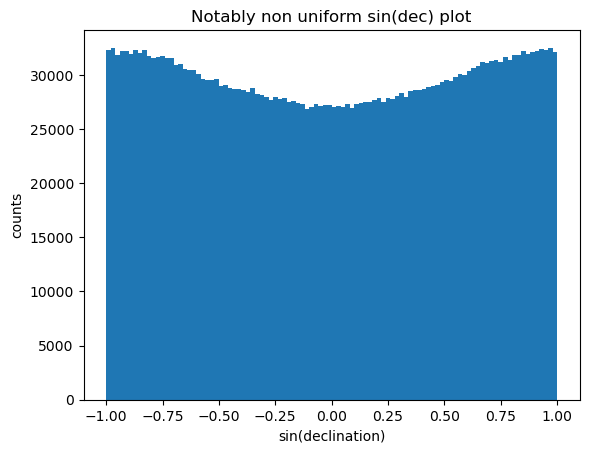

In [17]:
plt.hist(np.sin(dec), bins=100)
plt.title('Notably non uniform sin(dec) plot')
plt.xlabel('sin(declination)')
plt.ylabel('counts')


plt.show()

In [18]:
with h5py.File(filename, 'r') as f:  #reading in the file and making sure I dont read every row at once and blow up my computer
    events = f['events'] #shorthand again
    n_events = len(events)
    total = f.attrs['total_generated']
    accept = f.attrs['num_accepted']

print(total)
print(accept)
print(len(events))

870454872
8827136
2959534


Following cell is the code given in the appendix of the injections paper, not particularly useful for right now in terms of what it does but what its showing may prove useful in the coming weeks   


In [ ]:

#–––
# load the required data
with h5py.File(filename, 'r') as obj:
    events = obj['events'][:]
    meta = dict(obj.attrs.items())
#–––
# extract weights for mixture model
# see Essick, Research Notes of the AAS 5, 220 (2021).
weights = events['weights']
#–––
# extract p(m1, m2|draw)
pdraw = np.exp(events['lnpdraw_mass1_source']\
+ events['lnpdraw_mass2_source_GIVEN_mass1_source'])
# compute target distribution: flat in component masses between 10–20 Msun
# Note that we must include the proper normalization.
m1 = events['mass1_source']
m2 = events['mass2_source']
ptarget = (10 <= m1)*(m1 < 20)*(10 <= m2)*(m2 < 20) / (20-10)**2 / 2
#–––
### identify which events were detected using a FAR threshold
min_far = np.min([events["%s_far"%search] for search in \
meta["searches"]], axis=0)
detected = min_far < 1.0 # /year
### compute the Monte Carlo sum
pdet = np.sum(weights[detected] * ptarget[detected] / pdraw[detected]) \
/ meta["total_generated"]

# This is an example of how to compute detection efficiency for population over source frame component masses, taking injected distribution for every other parameter

This next cell was a test to see if the injections were definitely drawn isotropically, making sure that the way I have plotted it is definitely not the issue. Uses np.allclose to check that the log draw declination is equal to the cos(dec) which is indicative of an isotropic distribution 

In [15]:
with h5py.File(filename, 'r') as f:
    ev = f['events']
    dec = ev['declination'][:]
    lnp = ev['lnpdraw_declination'][:]
print(np.allclose(np.exp(lnp), np.cos(dec)/2))

True
